# 06 ML Dataset Validation and Experiment Design

This notebook validates the synthetic return-level dataset and prepares a leakage-safe experiment design. It does **not** fit, train, tune, or evaluate any model.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")

def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "src").exists() and (candidate / "data").exists():
            return candidate
    raise RuntimeError("Run this notebook from inside the EcomPolice project.")

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"


## Purpose and Prediction Task

The future task is a **simulated** suspicious-behaviour assessment when a customer submits a return request. The model would see information available by `Return_Request_Date`, not refund completion, return outcome, investigations, future returns, or generator labels.

The target is synthetic: each returned order is aligned to a generator-provided order label that is inherited from the customer scenario. It is not verified fraud and must not be presented as such.

In [2]:
from scripts.run_ml_dataset_validation import (
    TARGET_COLUMN,
    build_audit_tables,
    build_grouped_split,
    feature_columns,
    load_return_level_data,
    validate_grouped_split,
)

# Regenerate validation reports and deterministic split assignments; this does not train a model.
from scripts.run_ml_dataset_validation import main as run_ml_validation
run_ml_validation()

features, dataset = load_return_level_data()
audit = build_audit_tables(features, dataset)
assignments, split_summary = build_grouped_split(dataset)
split_validation = validate_grouped_split(assignments)

display(audit["overview"].to_frame("value"))
display(audit["target_distribution"])
display(audit["customer_distribution"])

records                                   3466
model_input_features                        16
numeric_features                            12
categorical_features                         4
duplicate_feature_ids                        0
feature_target_id_alignment               True
target_or_scenario_columns_in_features      []
customers_with_mixed_inherited_labels        0
     Split  records  customers  positive_records  positive_rate
     train     2079       1152               588         0.2828
validation      693        383               196         0.2828
      test      694        385               197         0.2839
all_customers_in_one_partition           True
customers_shared_across_partitions          0
all_partitions_non_empty                 True
both_target_classes_in_each_partition    True


,value
records,3466
model_input_features,16
numeric_features,12
categorical_features,4
duplicate_feature_ids,0
feature_target_id_alignment,True
target_or_scenario_columns_in_features,[]
customers_with_mixed_inherited_labels,0


,Simulated_Abuse_Target,return_requests,percentage
0,0,2485,71.7
1,1,981,28.3


,Simulated_Abuse_Target,unique_customers
0,0,1553
1,1,367


## Feature Matrix Audit

`Order_ID`, `Customer_ID`, and `Return_Request_Date` are retained for alignment, grouping, and audit only. They are excluded from the future model matrix. Scenario/target fields are in the separate target file and are checked below.

In [3]:
numeric_columns, categorical_columns, excluded_columns = feature_columns(features)
print("Numeric features:", numeric_columns)
print("Categorical features:", categorical_columns)
print("Excluded identifiers/timestamp:", excluded_columns)
print("Target/scenario fields found in feature inputs:", audit["overview"]["target_or_scenario_columns_in_features"])

display(audit["missing"])
display(audit["constants"])
display(audit["near_constants"])

Numeric features: ['Order_Value_INR', 'Days_Since_Delivery', 'Prior_Order_Count', 'Prior_Return_Count', 'Historical_Return_Rate', 'Recent_Return_Count_30D', 'Recent_Return_Count_90D', 'High_Value_Return_Count', 'Repeated_Defect_Claim_Rate', 'Average_Days_To_Return', 'Has_Prior_Order_History', 'Has_Prior_Return_History']
Categorical features: ['Product_Category', 'Payment_Method', 'Shipping_Method', 'Return_Reason']
Excluded identifiers/timestamp: ['Order_ID', 'Customer_ID', 'Return_Request_Date']
Target/scenario fields found in feature inputs: []


,feature,missing_count,missing_pct,dtype
0,Order_Value_INR,0,0.0,float64
1,Product_Category,0,0.0,object
2,Payment_Method,0,0.0,object
3,Shipping_Method,0,0.0,object
4,Return_Reason,0,0.0,object
5,Days_Since_Delivery,0,0.0,int64
6,Prior_Order_Count,0,0.0,int64
7,Prior_Return_Count,0,0.0,int64
8,Historical_Return_Rate,0,0.0,float64
9,Recent_Return_Count_30D,0,0.0,int64


,feature,unique_values,dominant_value_share


,feature,unique_values,dominant_value_share


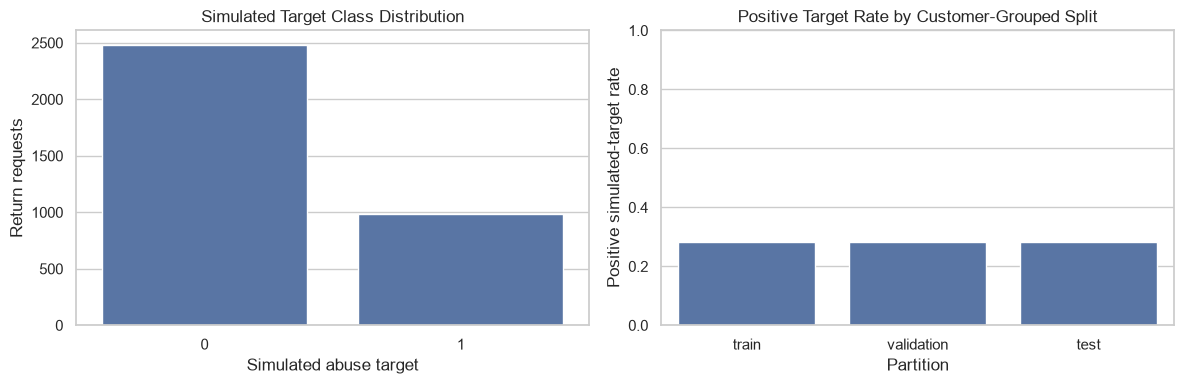

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=dataset, x=TARGET_COLUMN, ax=axes[0])
axes[0].set_title("Simulated Target Class Distribution")
axes[0].set_xlabel("Simulated abuse target")
axes[0].set_ylabel("Return requests")

split_plot = assignments.groupby("Split", observed=True)[TARGET_COLUMN].mean().reindex(["train", "validation", "test"]).reset_index()
sns.barplot(data=split_plot, x="Split", y=TARGET_COLUMN, ax=axes[1])
axes[1].set_title("Positive Target Rate by Customer-Grouped Split")
axes[1].set_xlabel("Partition")
axes[1].set_ylabel("Positive simulated-target rate")
axes[1].set_ylim(0, 1)
plt.tight_layout()
plt.show()

The overall target is moderately imbalanced, not extremely rare. Grouped splitting preserves customer isolation and produces nearly equal class rates across train, validation, and test. An ordinary random row split would be inappropriate because all returns from a customer share the inherited scenario label.

## Redundancy and Generator-Mechanism Checks

Highly correlated histories can be redundant for some future estimators. More importantly, strong association with this synthetic target may be evidence of how the generator was designed rather than evidence of a reliable real-world fraud signal.

In [5]:
display(audit["high_corr"])
display(audit["numeric_association"])
display(audit["categorical_association"])

customers_with_mixed_labels = dataset.groupby("Customer_ID")[TARGET_COLUMN].nunique().gt(1).sum()
print("Customers with returns carrying different inherited labels:", customers_with_mixed_labels)
print("Interpretation: zero is expected because the generator assigns the scenario at customer level.")

,feature_a,feature_b,spearman_correlation
2,Prior_Return_Count,Has_Prior_Return_History,0.9564
0,Prior_Return_Count,Historical_Return_Rate,0.9468
4,Historical_Return_Rate,Has_Prior_Return_History,0.9460
5,Average_Days_To_Return,Has_Prior_Return_History,0.9455
1,Prior_Return_Count,Average_Days_To_Return,0.9149
3,Historical_Return_Rate,Average_Days_To_Return,0.8959


,feature,point_biserial_like_pearson,abs_association
8,Repeated_Defect_Claim_Rate,0.4644,0.4644
9,Average_Days_To_Return,0.3401,0.3401
1,Days_Since_Delivery,0.3224,0.3224
7,High_Value_Return_Count,0.3088,0.3088
3,Prior_Return_Count,0.2910,0.2910
11,Has_Prior_Return_History,0.2292,0.2292
6,Recent_Return_Count_90D,0.2226,0.2226
4,Historical_Return_Rate,0.2183,0.2183
5,Recent_Return_Count_30D,0.1463,0.1463
2,Prior_Order_Count,0.1358,0.1358


,feature,levels,supported_target_rate_min,supported_target_rate_max,supported_target_rate_range
3,Return_Reason,8,0.1487,0.8085,0.6598
0,Product_Category,8,0.1925,0.4386,0.2461
1,Payment_Method,6,0.2514,0.2977,0.0463
2,Shipping_Method,3,0.2673,0.3000,0.0327


Customers with returns carrying different inherited labels: 0
Interpretation: zero is expected because the generator assigns the scenario at customer level.


## Leakage-Safe Evaluation Split

The split uses `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)`. One fold is test, one is validation, and three folds are training. Every `Customer_ID` appears in exactly one partition.

In [6]:
display(split_summary)
display(pd.Series(split_validation, name="passed_or_count"))

# This file is split metadata, not a model input table.
assignments.to_csv(PROCESSED_DIR / "return_level_split_assignments.csv", index=False)
print("Saved deterministic split assignments:", PROCESSED_DIR / "return_level_split_assignments.csv")

,Split,records,customers,positive_records,positive_rate
0,train,2079,1152,588,0.2828
1,validation,693,383,196,0.2828
2,test,694,385,197,0.2839


all_customers_in_one_partition           True
customers_shared_across_partitions          0
all_partitions_non_empty                 True
both_target_classes_in_each_partition    True
Name: passed_or_count, dtype: object

Saved deterministic split assignments: /Users/harshitmadhavpachauri/Documents/ChatGPT/EcomPolice/data/processed/return_level_split_assignments.csv


## Planned scikit-learn Preprocessing

This section defines preprocessing only. It deliberately does not call `.fit()` or attach a classifier.

- Numeric values will receive median imputation and scaling for a future linear baseline.
- Categorical values will receive most-frequent imputation and one-hot encoding with unknown categories ignored.
- The `ColumnTransformer` must be fitted on the grouped training partition only.
- A future estimator can be added as the final step of a `Pipeline` after the feature-ablation plan is approved.

In [7]:
numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("one_hot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_preprocessor, numeric_columns),
    ("categorical", categorical_preprocessor, categorical_columns),
], remainder="drop")

future_pipeline_plan = [
    "preprocess: ColumnTransformer fitted only on grouped training data",
    "estimator: intentionally not selected or fitted in this phase",
]
print(preprocessor)
print("\nFuture pipeline plan:")
for step in future_pipeline_plan:
    print("-", step)

ColumnTransformer(transformers=[('numeric',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Order_Value_INR', 'Days_Since_Delivery',
                                  'Prior_Order_Count', 'Prior_Return_Count',
                                  'Historical_Return_Rate',
                                  'Recent_Return_Count_30D',
                                  'Recent_Return_Count_90D',
                                  'High_Value_Return_Count',
                                  'Repeated_Defect_Claim_Rate',
                                  'Average_Days_To_Return',
                                  'Has_Prior_Order_History',
                                  'Has_Prior_Return_History']),
                                ('categorical',
                                 Pip

## Imbalance and Next Step

No oversampling has been applied. A future baseline should first use customer-grouped evaluation and class-sensitive metrics such as precision, recall, PR-AUC, and balanced accuracy. Class weights should be considered before any resampling. If SMOTE is ever evaluated, it must run inside training folds only.

Before training, compare a conservative feature set against an ablation that removes likely generator-mechanism signals such as current return reason and scenario-associated historical features. This will make the classroom experiment more honest and easier to explain.

In [8]:
print("Reports written:")
print(REPORTS_DIR / "ml_dataset_validation_report.md")
print(REPORTS_DIR / "ml_experiment_design.md")
print("\nNo model has been trained in this notebook.")

Reports written:
/Users/harshitmadhavpachauri/Documents/ChatGPT/EcomPolice/reports/ml_dataset_validation_report.md
/Users/harshitmadhavpachauri/Documents/ChatGPT/EcomPolice/reports/ml_experiment_design.md

No model has been trained in this notebook.
